### Loading the Dataset

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, tarfile
from tensorflow import keras

In [17]:
import os, pickle
import numpy as np

data_dir = os.path.expanduser("~/.keras/datasets/cifar-10-batches-py")

def load_batch(path):
    with open(path, "rb") as f:
        d = pickle.load(f, encoding="bytes")
    x = d[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(d[b"labels"], dtype=np.uint8).reshape(-1, 1)
    return x, y

batches = [load_batch(os.path.join(data_dir, f"data_batch_{i}")) for i in range(1, 6)]
x_train = np.concatenate([b[0] for b in batches])
y_train = np.concatenate([b[1] for b in batches])
x_test, y_test = load_batch(os.path.join(data_dir, "test_batch"))

print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)
# (50000, 32, 32, 3) (50000, 1) (10000, 32, 32, 3) (10000, 1)

(50000, 32, 32, 3) (50000, 1) (10000, 32, 32, 3) (10000, 1)


In [18]:
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(50000, 32, 32, 3) (50000, 1) (10000, 32, 32, 3) (10000, 1)


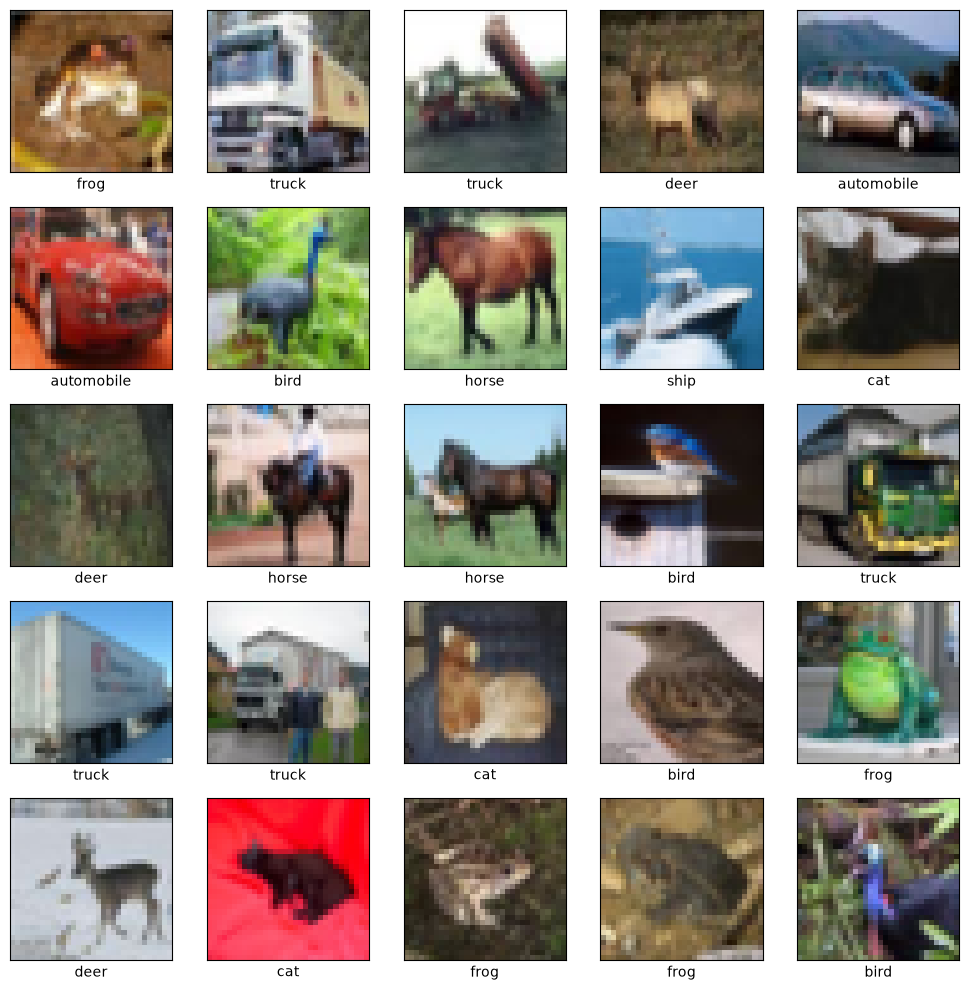

In [19]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[y_train[i][0]])
plt.tight_layout()
plt.show()